# Telecom Customer Churn Prediction – Model Improvement

## 1. Introduction

In this notebook, we will explore techniques to improve the performance of our baseline machine learning models.

During the initial analysis, we identified class imbalance in the target variable, where the number of customers who stayed was significantly higher than the number of customers who churned.

This can affect the model's ability to identify potential churners.

### Model Improvement Techniques

1. Handling class imbalance using class weights.
2. Hyperparameter tuning.
3. Cross-validation.
4. Classification threshold optimization.

### Objective

To improve the model's ability to identify customers who are likely to churn while maintaining a reasonable balance between precision and recall.

## 2. Handling Class Imbalance

Class imbalance occurs when one target class has significantly more observations than another.

In our telecom churn dataset:

- No Churn: 73.46%
- Churn: 26.54%

Since the number of customers who churn is lower, the model may not identify the minority class effectively.

To address this issue, we will experiment with the `class_weight="balanced"` parameter.

This parameter automatically adjusts class weights based on the frequency of each class, giving greater importance to the minority class during model training.

Our objective is to improve the identification of customers who are likely to churn.

In [1]:
import pandas as pd
from scipy.sparse import load_npz

# Load the processed training features
X_train = load_npz("../data/processed/X_train_processed.npz")

# Load the training target
y_train = pd.read_csv("../data/processed/y_train.csv").squeeze()

# Check the shapes
print("Training features shape:", X_train.shape)
print("Training target shape:", y_train.shape)

Training features shape: (5634, 46)
Training target shape: (5634,)


### 2.1 Training Logistic Regression with Balanced Class Weights

We will train a Logistic Regression model using `class_weight="balanced"`.

This setting automatically calculates class weights based on the frequency of each class. It gives more importance to the minority class (Churn = Yes) during training.

We will later compare its performance with our baseline Logistic Regression model to understand whether class weighting improves churn detection.

In [2]:
from sklearn.linear_model import LogisticRegression

# Create the balanced Logistic Regression model
logistic_balanced = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)

# Train the model
logistic_balanced.fit(X_train, y_train)

print("Balanced Logistic Regression model trained successfully!")

Balanced Logistic Regression model trained successfully!


In [3]:
print("Classes:", logistic_balanced.classes_)
print("Class weights:", logistic_balanced.class_weight)

print("Actual class distribution:")
print(y_train.value_counts())

Classes: ['No' 'Yes']
Class weights: balanced
Actual class distribution:
Churn
No     4139
Yes    1495
Name: count, dtype: int64


In [4]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

classes = np.array(["No", "Yes"])

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

for class_name, weight in zip(classes, weights):
    print(f"{class_name}: {weight:.3f}")

No: 0.681
Yes: 1.884


### 2.2 Understanding the Calculated Class Weights

Using Scikit-learn's `compute_class_weight()` function, we calculated the weights assigned to each class.

| Class | Weight |
|---|---:|
| No | 0.681 |
| Yes | 1.884 |

The minority class (`Yes`) receives a higher weight than the majority class (`No`).

This encourages the model to pay more attention to customers who are likely to churn during training.

The next step is to evaluate whether this approach improves churn detection compared with our baseline model.

### 2.3 Evaluating the Balanced Logistic Regression Model

After training the Logistic Regression model with balanced class weights, we will evaluate its performance using the test dataset.

We will examine the following metrics:

- Accuracy
- Precision
- Recall
- F1-score
- ROC-AUC

Special attention will be given to recall because identifying customers who are likely to churn is an important business objective.

We will compare these results with our baseline Logistic Regression model to understand the impact of class weighting.

In [5]:
from scipy.sparse import load_npz
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Load test data
X_test = load_npz("../data/processed/X_test_processed.npz")
y_test = pd.read_csv("../data/processed/y_test.csv").squeeze()

# Generate predictions
y_pred_balanced = logistic_balanced.predict(X_test)

# Generate churn probabilities
y_prob_balanced = logistic_balanced.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics
print("Balanced Logistic Regression Results")
print("------------------------------------")
print("Accuracy:", accuracy_score(y_test, y_pred_balanced))
print("Precision:", precision_score(y_test, y_pred_balanced, pos_label="Yes"))
print("Recall:", recall_score(y_test, y_pred_balanced, pos_label="Yes"))
print("F1-score:", f1_score(y_test, y_pred_balanced, pos_label="Yes"))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_balanced))

Balanced Logistic Regression Results
------------------------------------
Accuracy: 0.7381121362668559
Precision: 0.504302925989673
Recall: 0.7834224598930482
F1-score: 0.6136125654450262
ROC-AUC: 0.841501976284585


### 2.4 Comparison: Baseline vs Balanced Logistic Regression

After applying class weights, we observed the following changes:

| Metric | Baseline | Balanced |
|---|---:|---:|
| Accuracy | 80.55% | 73.81% |
| Precision | 65.72% | 50.43% |
| Recall | 55.88% | 78.34% |
| F1-score | 60.40% | 61.36% |
| ROC-AUC | 84.20% | 84.15% |

**Key Findings:**

1. Recall increased from 55.88% to 78.34%, indicating that the balanced model identifies a larger proportion of actual churners.
2. Precision decreased from 65.72% to 50.43%, meaning more customers predicted to churn are actually non-churners.
3. Accuracy decreased from 80.55% to 73.81%.
4. F1-score improved slightly from 60.40% to 61.36%.
5. ROC-AUC remained almost unchanged.

**Conclusion:**

Class weighting improved the model's ability to identify customers who are likely to churn. However, this improvement came at the cost of lower precision and accuracy.

The balanced model may be more suitable when identifying potential churners is a higher priority than avoiding false alarms.

### 2.5 Confusion Matrix Analysis

A confusion matrix is used to evaluate the classification performance of a machine learning model.

It compares the actual target values with the predicted values.

The four outcomes are:

- True Positive (TP): Actual churn customers correctly predicted as churn.
- True Negative (TN): Actual non-churn customers correctly predicted as non-churn.
- False Positive (FP): Non-churn customers incorrectly predicted as churn.
- False Negative (FN): Churn customers incorrectly predicted as non-churn.

This analysis helps us understand the types of mistakes made by the model.

### 2.5 Confusion Matrix Analysis

A confusion matrix is used to evaluate the classification performance of a machine learning model.

It compares the actual target values with the predicted values.

The four outcomes are:

- True Positive (TP): Actual churn customers correctly predicted as churn.
- True Negative (TN): Actual non-churn customers correctly predicted as non-churn.
- False Positive (FP): Non-churn customers incorrectly predicted as churn.
- False Negative (FN): Churn customers incorrectly predicted as non-churn.

This analysis helps us understand the types of mistakes made by the model.

[[747 288]
 [ 81 293]]


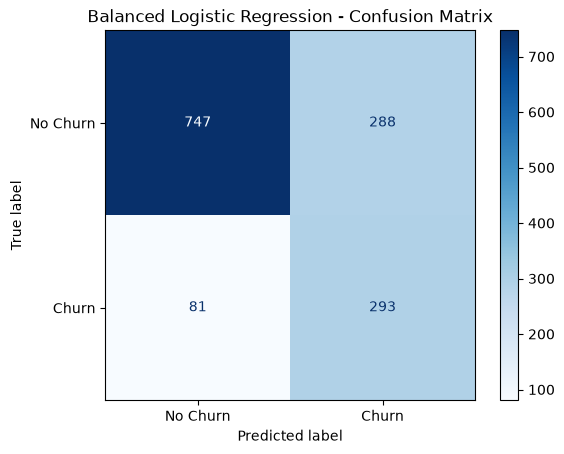

In [6]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Generate confusion matrix
cm_balanced = confusion_matrix(
    y_test,
    y_pred_balanced,
    labels=["No", "Yes"]
)

print(cm_balanced)

# Visualize confusion matrix
display = ConfusionMatrixDisplay(
    confusion_matrix=cm_balanced,
    display_labels=["No Churn", "Churn"]
)

display.plot(cmap="Blues")
plt.title("Balanced Logistic Regression - Confusion Matrix")
plt.show()

### 2.6 Findings from the Confusion Matrix

The confusion matrix of the balanced Logistic Regression model produced the following results:

- True Negative: 747
- False Positive: 288
- False Negative: 81
- True Positive: 293

**Key Observations:**

1. The model correctly identified 293 customers who actually churned.
2. It missed only 81 actual churners.
3. It incorrectly classified 288 customers who stayed as potential churners.
4. Compared with the baseline model, it identified 84 additional churners and reduced missed churn cases from 165 to 81.

**Business Interpretation:**

Class weighting helped the model identify more customers who are likely to discontinue their subscriptions.

However, the increase in false positives may lead to additional retention campaign expenses.

Therefore, the choice between baseline and balanced Logistic Regression depends on the business's preference for identifying more churners versus controlling unnecessary retention costs.

## 3. Hyperparameter Tuning

Hyperparameter tuning is the process of finding the most suitable settings for a machine learning algorithm to improve its performance.

Unlike model parameters, which are learned during training, hyperparameters are specified before the training process.

In this project, we will experiment with different Logistic Regression hyperparameters to identify a suitable model configuration.

### Objectives

1. Experiment with different regularization strengths.
2. Apply cross-validation to evaluate different configurations.
3. Identify a suitable combination of hyperparameters.
4. Compare the tuned model with our baseline and balanced models.

We will use the training dataset for model selection and keep the test dataset separate during tuning.

### 3.1 Understanding Cross-Validation

Cross-validation is a model evaluation technique used to assess how consistently a machine learning model performs across different subsets of the training data.

In this project, we will use Stratified 5-Fold Cross-Validation.

The process involves:

1. Dividing the training dataset into five folds.
2. Training the model using four folds.
3. Evaluating the model using the remaining fold.
4. Repeating the process five times, using a different validation fold each time.
5. Calculating the average performance across all five folds.

Stratified cross-validation maintains approximately the same proportion of churn and non-churn customers in each fold.

This helps us compare different hyperparameter settings more reliably while preserving the class distribution.

In [9]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import recall_score, make_scorer

# Create a custom recall scorer for the Yes class
recall_scorer = make_scorer(
    recall_score,
    pos_label="Yes"
)

# Create Stratified 5-Fold Cross-Validation
skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Create balanced Logistic Regression model
cv_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)

# Perform cross-validation
cv_scores = cross_val_score(
    cv_model,
    X_train,
    y_train,
    cv=skf,
    scoring=recall_scorer
)

# Display results
print("Recall scores for each fold:", cv_scores)
print("Average Recall:", cv_scores.mean())
print("Standard Deviation:", cv_scores.std())

Recall scores for each fold: [0.82608696 0.74916388 0.7993311  0.85284281 0.77926421]
Average Recall: 0.8013377926421406
Standard Deviation: 0.035996318520598564


### 3.2 Stratified 5-Fold Cross-Validation Results

We performed Stratified 5-Fold Cross-Validation on the balanced Logistic Regression model using recall as the evaluation metric.

**Results:**

| Fold | Recall |
|---|---:|
| Fold 1 | 82.61% |
| Fold 2 | 74.92% |
| Fold 3 | 79.93% |
| Fold 4 | 85.28% |
| Fold 5 | 77.93% |

- Average Recall: 80.13%
- Standard Deviation: 3.60%

**Key Findings:**

1. The model achieved an average recall of 80.13% across five validation folds.
2. Recall varied between 74.92% and 85.28%.
3. The standard deviation of 3.60 percentage points indicates relatively consistent recall across the folds.

**Conclusion:**

Stratified cross-validation provides a more reliable understanding of model performance across different training and validation splits.

We will use this approach to compare different hyperparameter configurations.

### 3.3 Hyperparameter Tuning using GridSearchCV

GridSearchCV is a hyperparameter optimization technique provided by Scikit-learn.

It systematically evaluates different combinations of hyperparameter values using cross-validation.

In this project, we will tune the regularization parameter `C` of Logistic Regression.

The parameter `C` controls the strength of regularization:

- Smaller values of C apply stronger regularization.
- Larger values of C apply weaker regularization.

We will use Stratified 5-Fold Cross-Validation and recall as the scoring metric to identify a suitable configuration for churn detection.

In [10]:
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import make_scorer, recall_score

# Define hyperparameter values
param_grid = {
    "C": [0.01, 0.1, 1, 10, 100]
}

# Create balanced Logistic Regression
logistic_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)

# Create GridSearchCV
grid_search = GridSearchCV(
    estimator=logistic_model,
    param_grid=param_grid,
    cv=skf,
    scoring=make_scorer(recall_score, pos_label="Yes"),
    n_jobs=-1,
    verbose=1
)

# Perform hyperparameter tuning
grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best Cross-Validation Recall:", grid_search.best_score_)

Fitting 5 folds for each of 5 candidates, totalling 25 fits
Best Parameters: {'C': 1}
Best Cross-Validation Recall: 0.8013377926421406


### 3.4 GridSearchCV Results

We performed hyperparameter tuning using GridSearchCV with Stratified 5-Fold Cross-Validation.

The following values of the regularization parameter `C` were evaluated:

`[0.01, 0.1, 1, 10, 100]`

**Results:**

- Total hyperparameter candidates: 5
- Cross-validation folds: 5
- Total model fits: 25
- Best parameter: C = 1
- Best cross-validation recall: 80.13%

**Key Findings:**

GridSearchCV selected `C = 1` as the best configuration among the tested values.

The best recall was 80.13%, which is identical to the earlier cross-validation result for balanced Logistic Regression.

This indicates that the default regularization setting performed best among the configurations evaluated.

**Conclusion:**

Hyperparameter tuning confirmed that `C = 1` is a suitable configuration among the tested values. However, it did not produce an improvement in cross-validation recall.

In [12]:
# Convert GridSearchCV results into a DataFrame
results = pd.DataFrame(grid_search.cv_results_)

# Select important columns
results = results[
    [
        "param_C",
        "mean_test_score",
        "std_test_score",
        "rank_test_score"
    ]
]

# Rename columns
results.columns = [
    "C Value",
    "Mean Recall",
    "Standard Deviation",
    "Rank"
]

# Sort results by rank
results = results.sort_values(by="Rank")

results

,C Value,Mean Recall,Standard Deviation,Rank
2,1.00,0.801338,0.035996,1
3,10.00,0.800000,0.037921,2
4,100.00,0.800000,0.037921,2
1,0.10,0.796656,0.034975,4
0,0.01,0.789967,0.032796,5


### 3.5 Comparison of Hyperparameter Configurations

We compared five different values of the Logistic Regression regularization parameter `C` using Stratified 5-Fold Cross-Validation.

**Results:**

| C Value | Mean Recall | Standard Deviation | Rank |
|---|---:|---:|---:|
| 0.01 | 78.997% | 3.280% | 5 |
| 0.1 | 79.666% | 3.498% | 4 |
| 1 | 80.134% | 3.600% | 1 |
| 10 | 80.000% | 3.792% | 2 |
| 100 | 80.000% | 3.792% | 2 |

**Key Findings:**

1. C = 1 achieved the highest average recall of 80.13%.
2. C = 10 and C = 100 achieved slightly lower recall values of 80%.
3. C = 0.01 produced the lowest average recall.
4. Increasing C beyond 1 did not improve the model's recall.

**Conclusion:**

Among the tested configurations, C = 1 performed best in terms of average recall. Therefore, we will retain this configuration for further model evaluation.

In [13]:
# Retrieve the best model
best_logistic_model = grid_search.best_estimator_

# Display its configuration
print("Best Model:", best_logistic_model)

# Save the tuned model
import joblib

joblib.dump(
    best_logistic_model,
    "../models/tuned_logistic_regression.pkl"
)

print("Tuned Logistic Regression model saved successfully!")

Best Model: LogisticRegression(C=1, class_weight='balanced', max_iter=1000)
Tuned Logistic Regression model saved successfully!


In [14]:
import os

model_path = "../models/tuned_logistic_regression.pkl"

if os.path.exists(model_path):
    print("Tuned model file exists!")
else:
    print("Model file not found!")

Tuned model file exists!


### 3.6 Saving and Verifying the Tuned Model

After completing hyperparameter tuning, we retrieved the best Logistic Regression estimator using `grid_search.best_estimator_`.

The selected configuration was:

- C = 1
- Class Weight = Balanced
- Maximum Iterations = 1000

The trained model was saved as `tuned_logistic_regression.pkl` in the models directory.

The file was successfully verified.

This saved model will be used for further evaluation and comparison.

In [15]:
import joblib

# Load the tuned Logistic Regression model
tuned_model = joblib.load(
    "../models/tuned_logistic_regression.pkl"
)

# Generate predictions
y_pred_tuned = tuned_model.predict(X_test)

# Generate churn probabilities
y_prob_tuned = tuned_model.predict_proba(X_test)[:, 1]

print("Tuned model loaded successfully!")
print("Predictions generated successfully!")
print("Total predictions:", len(y_pred_tuned))

Tuned model loaded successfully!
Predictions generated successfully!
Total predictions: 1409


In [16]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

print("Tuned Logistic Regression Results")
print("---------------------------------")

print("Accuracy:", accuracy_score(y_test, y_pred_tuned))

print("Precision:", precision_score(
    y_test, y_pred_tuned, pos_label="Yes"
))

print("Recall:", recall_score(
    y_test, y_pred_tuned, pos_label="Yes"
))

print("F1-score:", f1_score(
    y_test, y_pred_tuned, pos_label="Yes"
))

print("ROC-AUC:", roc_auc_score(y_test, y_prob_tuned))

Tuned Logistic Regression Results
---------------------------------
Accuracy: 0.7381121362668559
Precision: 0.504302925989673
Recall: 0.7834224598930482
F1-score: 0.6136125654450262
ROC-AUC: 0.841501976284585


### 3.7 Tuned Logistic Regression Evaluation

After retrieving the best estimator from GridSearchCV, we evaluated the tuned Logistic Regression model using the test dataset.

**Performance Results:**

| Metric | Baseline | Balanced | Tuned |
|---|---:|---:|---:|
| Accuracy | 80.55% | 73.81% | 73.81% |
| Precision | 65.72% | 50.43% | 50.43% |
| Recall | 55.88% | 78.34% | 78.34% |
| F1-score | 60.40% | 61.36% | 61.36% |
| ROC-AUC | 84.20% | 84.15% | 84.15% |

**Key Findings:**

1. The tuned model achieved 78.34% recall.
2. Its performance was identical to the balanced Logistic Regression model.
3. GridSearchCV selected C = 1, which was already the configuration used by the balanced model.
4. Hyperparameter tuning did not produce an additional performance improvement.

**Conclusion:**

Balanced Logistic Regression currently provides the strongest churn recall among our evaluated models. Hyperparameter tuning confirmed that the existing configuration was already the best among the tested values.

## 4. Classification Threshold Optimization

Classification threshold optimization is a technique used to adjust the decision boundary of a classification model.

By default, Logistic Regression uses a threshold of 0.5 to classify customers.

- Probability greater than or equal to 0.5: Churn (Yes).
- Probability below 0.5: No Churn (No).

However, we can experiment with different threshold values to influence the model's predictions.

A lower threshold generally increases recall but may reduce precision.

A higher threshold generally increases precision but may reduce recall.

### Objective

To identify a suitable classification threshold that improves the balance between precision and recall while considering the business objective of identifying potential churners.

In [17]:
# Display the first 10 churn probabilities
print("First 10 churn probabilities:")
print(y_prob_tuned[:10])

# Display minimum and maximum probabilities
print("\nMinimum probability:", y_prob_tuned.min())
print("Maximum probability:", y_prob_tuned.max())

# Display average churn probability
print("Average churn probability:", y_prob_tuned.mean())

First 10 churn probabilities:
[0.11708765 0.8523775  0.14648819 0.66050569 0.06088137 0.80587817
 0.69782619 0.2928241  0.00918461 0.65240749]

Minimum probability: 0.005683971589716719
Maximum probability: 0.9379780291727129
Average churn probability: 0.4157812680233761


### 4.1 Understanding Predicted Churn Probabilities

The tuned Logistic Regression model generates churn probabilities for each customer using `predict_proba()`.

The first ten predicted churn probabilities were examined.

**Summary:**

- Minimum churn probability: 0.57%
- Maximum churn probability: 93.80%
- Average predicted churn probability: 41.58%

These probabilities represent the model's estimated likelihood that a customer belongs to the churn class.

Using the default threshold of 0.5:

- Probability greater than or equal to 0.5: Churn (Yes).
- Probability below 0.5: No Churn (No).

These probability scores will help us experiment with different classification thresholds and understand their impact on precision and recall.

In [18]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd
import numpy as np

# Define threshold values
thresholds = [0.3, 0.4, 0.5, 0.6, 0.7]

# Store results
threshold_results = []

for threshold in thresholds:

    # Convert probabilities into class predictions
    y_pred_threshold = np.where(
        y_prob_tuned >= threshold,
        "Yes",
        "No"
    )

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_test, y_pred_threshold)
    precision = precision_score(
        y_test, y_pred_threshold, pos_label="Yes"
    )
    recall = recall_score(
        y_test, y_pred_threshold, pos_label="Yes"
    )
    f1 = f1_score(
        y_test, y_pred_threshold, pos_label="Yes"
    )

    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1
    })

# Create comparison table
threshold_df = pd.DataFrame(threshold_results)

threshold_df

,Threshold,Accuracy,Precision,Recall,F1-score
0,0.3,0.653655,0.429455,0.927807,0.587140
1,0.4,0.701916,0.466859,0.866310,0.606742
2,0.5,0.738112,0.504303,0.783422,0.613613
3,0.6,0.762243,0.539877,0.705882,0.611819
4,0.7,0.789212,0.603217,0.601604,0.602410


### 4.2 Comparison of Classification Thresholds

We experimented with five classification thresholds: 0.3, 0.4, 0.5, 0.6 and 0.7.

**Results:**

| Threshold | Accuracy | Precision | Recall | F1-score |
|---|---:|---:|---:|---:|
| 0.3 | 65.37% | 42.95% | 92.78% | 58.71% |
| 0.4 | 70.19% | 46.69% | 86.63% | 60.67% |
| 0.5 | 73.81% | 50.43% | 78.34% | 61.36% |
| 0.6 | 76.22% | 53.99% | 70.59% | 61.18% |
| 0.7 | 78.92% | 60.32% | 60.16% | 60.24% |

**Key Findings:**

1. Threshold 0.3 achieved the highest recall of 92.78%.
2. Threshold 0.5 achieved the highest F1-score of 61.36%.
3. Threshold 0.7 achieved the highest accuracy and precision.
4. Lower thresholds increased recall but reduced precision.
5. Higher thresholds increased precision but reduced recall.

**Conclusion:**

Classification threshold selection depends on the business objective.

A threshold of 0.3 may be suitable when identifying more potential churners is the priority, while 0.5 provides the best F1-score among the tested thresholds.

Further evaluation of business costs and benefits is required before selecting the final operating threshold.

Confusion Matrix at Threshold 0.3:
[[574 461]
 [ 27 347]]


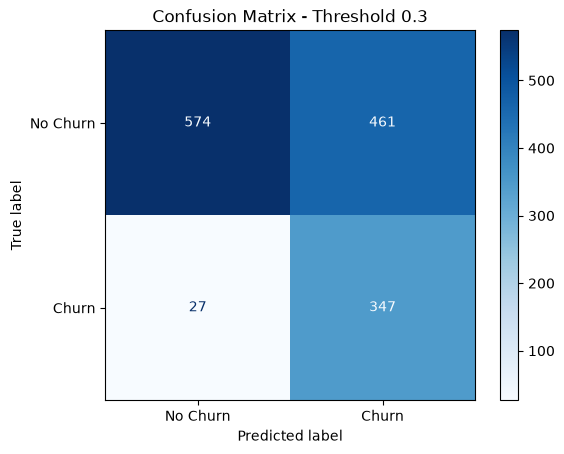

In [19]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import numpy as np
import matplotlib.pyplot as plt

# Set threshold
selected_threshold = 0.3

# Generate predictions using threshold 0.3
y_pred_03 = np.where(
    y_prob_tuned >= selected_threshold,
    "Yes",
    "No"
)

# Generate confusion matrix
cm_03 = confusion_matrix(
    y_test,
    y_pred_03,
    labels=["No", "Yes"]
)

print("Confusion Matrix at Threshold 0.3:")
print(cm_03)

# Visualize confusion matrix
display = ConfusionMatrixDisplay(
    confusion_matrix=cm_03,
    display_labels=["No Churn", "Churn"]
)

display.plot(cmap="Blues")
plt.title("Confusion Matrix - Threshold 0.3")
plt.show()

### 10.3 Confusion Matrix Analysis at Threshold 0.3

The confusion matrix at a classification threshold of 0.3 produced the following results:

- True Negatives: 574
- False Positives: 461
- False Negatives: 27
- True Positives: 347

Compared with the default threshold of 0.5, the threshold of 0.3 identified 54 additional customers who actually churned and reduced false negatives from 81 to 27.

However, false positives increased from 288 to 461.

**Business Interpretation:**

A threshold of 0.3 may be useful when the business prioritizes identifying as many potential churners as possible. This can help the company reach more at-risk customers through retention campaigns.

However, it also increases the number of unnecessary retention offers, potentially increasing marketing costs.

Therefore, threshold selection should consider the business costs associated with false positives and false negatives.

## 11. Final Model Comparison

In this section, we compare the performance of our baseline models and improved Logistic Regression models.

The comparison considers the following evaluation metrics:

- Accuracy
- Precision
- Recall
- F1-score
- ROC-AUC

Since identifying potential churners is an important business objective, particular attention will be given to Recall and F1-score.

The objective is to identify a model that provides a reasonable balance between detecting churners and avoiding unnecessary retention campaigns.

In [22]:
from IPython.display import display as show_table

show_table(comparison_df.round(4))

,Model,Accuracy,Precision,Recall,F1_Score,ROC_AUC
0,Logistic Regression (Baseline),0.8055,0.6572,0.5588,0.6040,0.8420
1,Decision Tree,0.7225,0.4777,0.4866,0.4821,0.6469
2,Random Forest,0.7885,0.6310,0.4893,0.5512,0.8201
3,Logistic Regression (Balanced),0.7381,0.5043,0.7834,0.6136,0.8415
4,Logistic Regression (Tuned),0.7381,0.5043,0.7834,0.6136,0.8415
5,Logistic Regression (Threshold 0.3),0.6537,0.4295,0.9278,0.5871,NaN


### 11.1 Final Model Comparison – Observations

The comparison of different machine learning approaches produced the following observations:

1. Baseline Logistic Regression achieved the highest accuracy of 80.55% among the initial models.
2. Balanced Logistic Regression improved churn recall from 55.88% to 78.34%.
3. Hyperparameter tuning selected C=1, which was already the default setting. Therefore, no additional performance improvement was observed.
4. Reducing the classification threshold to 0.3 increased recall to 92.78%, but reduced precision to 42.95%.
5. Decision Tree performed comparatively poorly, with an ROC-AUC score of 64.69%.

**Final Selection:**

Balanced Logistic Regression is selected as the primary model for further evaluation because it provides a better balance between precision and recall while identifying more potential churners than the baseline model.

A classification threshold of 0.3 can also be considered when the business prioritizes identifying as many potential churners as possible, provided the additional retention campaign costs are acceptable.

The final threshold should ultimately be selected based on business costs and validated using separate validation data.

## 12. Customer Churn Risk Scoring

In this section, we use the trained Logistic Regression model to calculate churn probabilities for individual customers.

Instead of producing only a binary prediction (Yes or No), the model provides a probability score indicating how likely a customer is to churn.

Based on these scores, customers can be grouped into different risk categories:

- **High Risk:** Customers with a high predicted probability of churn.
- **Medium Risk:** Customers with a moderate predicted probability of churn.
- **Low Risk:** Customers with a low predicted probability of churn.

### Objective

To generate customer-level churn risk scores that can help telecom companies prioritize retention campaigns and make data-driven business decisions.

In [23]:
# Load the original cleaned dataset
df_original = pd.read_csv(
    "../data/processed/cleaned_telco_data.csv"
)

# Display the first five customer IDs
df_original[["customerID"]].head()

,customerID
0,7590-VHVEG
1,5575-GNVDE
2,3668-QPYBK
3,7795-CFOCW
4,9237-HQITU


In [24]:
from sklearn.model_selection import train_test_split

# Separate customer IDs
customer_ids = df_original["customerID"]

# Recreate the original train-test split
_, customer_ids_test = train_test_split(
    customer_ids,
    test_size=0.20,
    random_state=42,
    stratify=df_original["Churn"]
)

# Reset index for easier alignment
customer_ids_test = customer_ids_test.reset_index(drop=True)

# Display first five test customer IDs
customer_ids_test.head()

0    4376-KFVRS
1    2754-SDJRD
2    9917-KWRBE
3    0365-GXEZS
4    9385-NXKDA
Name: customerID, dtype: str

In [25]:
print("Number of test customer IDs:", len(customer_ids_test))
print("Number of test predictions:", len(y_pred_tuned))
print("Number of churn probabilities:", len(y_prob_tuned))

Number of test customer IDs: 1409
Number of test predictions: 1409
Number of churn probabilities: 1409


In [26]:
# Create customer churn risk DataFrame
churn_risk_df = pd.DataFrame({
    "CustomerID": customer_ids_test,
    "Actual_Churn": y_test.reset_index(drop=True),
    "Predicted_Churn": y_pred_tuned,
    "Churn_Probability": y_prob_tuned
})

# Display first 10 records
churn_risk_df.head(10)

,CustomerID,Actual_Churn,Predicted_Churn,Churn_Probability
0,4376-KFVRS,No,No,0.117088
1,2754-SDJRD,No,Yes,0.852378
2,9917-KWRBE,No,No,0.146488
3,0365-GXEZS,No,Yes,0.660506
4,9385-NXKDA,No,No,0.060881
5,4686-UXDML,No,Yes,0.805878
6,2227-JRSJX,No,Yes,0.697826
7,4830-FAXFM,No,No,0.292824
8,1830-IPXVJ,No,No,0.009185
9,4690-LLKUA,Yes,Yes,0.652407


In [27]:
def categorize_risk(probability):
    if probability >= 0.70:
        return "High Risk"
    elif probability >= 0.30:
        return "Medium Risk"
    else:
        return "Low Risk"


churn_risk_df["Risk_Level"] = (
    churn_risk_df["Churn_Probability"].apply(categorize_risk)
)

churn_risk_df.head(10)

,CustomerID,Actual_Churn,Predicted_Churn,Churn_Probability,Risk_Level
0,4376-KFVRS,No,No,0.117088,Low Risk
1,2754-SDJRD,No,Yes,0.852378,High Risk
2,9917-KWRBE,No,No,0.146488,Low Risk
3,0365-GXEZS,No,Yes,0.660506,Medium Risk
4,9385-NXKDA,No,No,0.060881,Low Risk
5,4686-UXDML,No,Yes,0.805878,High Risk
6,2227-JRSJX,No,Yes,0.697826,Medium Risk
7,4830-FAXFM,No,No,0.292824,Low Risk
8,1830-IPXVJ,No,No,0.009185,Low Risk
9,4690-LLKUA,Yes,Yes,0.652407,Medium Risk


In [28]:
risk_distribution = churn_risk_df["Risk_Level"].value_counts()

print("Customer Churn Risk Distribution:")
print(risk_distribution)

Customer Churn Risk Distribution:
Risk_Level
Low Risk       601
Medium Risk    435
High Risk      373
Name: count, dtype: int64


In [32]:
# Calculate customer count for each risk category
risk_counts = churn_risk_df["Risk_Level"].value_counts()

# Calculate percentage distribution
risk_percentages = (
    churn_risk_df["Risk_Level"].value_counts(normalize=True) * 100
)

# Combine counts and percentages
risk_summary = pd.DataFrame({
    "Customer_Count": risk_counts,
    "Percentage": risk_percentages
})

from IPython.display import display as show_table
print("Customer Churn Risk Summary:")
show_table(risk_summary.round(2))

Customer Churn Risk Summary:


,Customer_Count,Percentage
Risk_Level,,
Low Risk,601,42.65
Medium Risk,435,30.87
High Risk,373,26.47


### 12.7 Customer Churn Risk Distribution Analysis

The test dataset contains 1,409 customers categorized into three churn risk levels.

| Risk Category | Customer Count | Percentage |
|---|---:|---:|
| Low Risk | 601 | 42.65% |
| Medium Risk | 435 | 30.87% |
| High Risk | 373 | 26.47% |

**Business Insights:**

1. High-risk customers represent 26.47% of the test dataset and can be prioritized for retention campaigns.
2. Medium-risk customers represent 30.87% and can be monitored through targeted engagement.
3. Low-risk customers represent 42.65% and may require regular customer engagement rather than immediate retention offers.

This risk segmentation helps telecom companies allocate retention resources based on predicted customer churn likelihood.

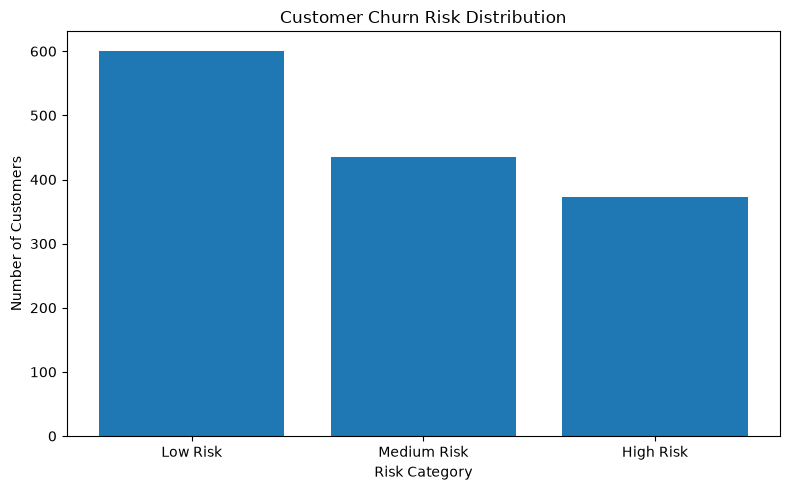

In [33]:
import matplotlib.pyplot as plt

# Get risk category counts
risk_counts = churn_risk_df["Risk_Level"].value_counts()

# Create bar chart
plt.figure(figsize=(8, 5))

plt.bar(
    risk_counts.index,
    risk_counts.values
)

plt.title("Customer Churn Risk Distribution")
plt.xlabel("Risk Category")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

In [34]:
# Save customer churn risk scores
churn_risk_df.to_csv(
    "../reports/customer_churn_risk_scores.csv",
    index=False
)

print("Customer churn risk scores saved successfully!")

Customer churn risk scores saved successfully!


In [35]:
import os

file_path = "../reports/customer_churn_risk_scores.csv"

if os.path.exists(file_path):
    print("File exists!")
    print("File size:", os.path.getsize(file_path), "bytes")
else:
    print("File not found!")

File exists!
File size: 68174 bytes
